<a href="https://colab.research.google.com/github/Gayathridevi-gj/App-User-Behavior-Segmentation-Using-Unsupervised-Machine-Learning/blob/main/project_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Packages

In [4]:
import pandas as pd

import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore

Data Loading

In [5]:
df=pd.read_csv('/content/app_user_behavior_dataset.csv')
df

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,5,8,8,1,0,20,Basic,9,5,2,NaN,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,7,3,7,0,0,7,Free,8,3,3,3.0,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,5,2,21,1,0,33,Free,11,6,1,2.0,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,8,4,13,0,0,17,Basic,6,3,1,3.0,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,7,3,15,0,0,21,Basic,4,4,2,5.0,0.43,38.21,772,Email Campaign
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149995,23,Male,Germany,Android,1.1,10,8.68,70.21,15,4,4,22,0,1,9,Free,4,0,1,4.0,0.39,68.97,121,Google Ads
49996,149996,34,Female,India,iOS,1.1,6,3.30,41.51,9,4,3,17,0,1,10,Basic,5,5,1,5.0,0.12,64.84,133,Google Ads
49997,149997,43,Male,India,iOS,1.2,6,21.67,58.00,9,6,3,14,0,0,27,Free,9,1,2,1.0,0.60,69.70,1120,Google Ads
49998,149998,41,Male,India,iOS,1.2,13,14.29,37.93,10,4,5,12,0,0,11,Free,6,2,2,4.0,0.22,71.00,1175,Google Ads


In [6]:
pd.set_option('display.max_columns', None)

Data Understanding using ydata profiling

In [ ]:
!pip install ydata_profiling
!pip install fg-data-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 33.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 45.2 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 22.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 77.5 MB/s  0:00:00
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.46.0
    Uninstalling llvmlite-0.46.0:
      Successfully uninstalled llvmlite-0.46.0
  Attempting uninstall: numba
    Found existing installation: numba 0.64.0
    Uninstalling numba-0.64.0:
      Successfully uninstalled numba-0.64.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [ydata_profiling]


In [ ]:
!pip install "numpy<2.4"

# Programmatically restart the Colab runtime session to apply the downgraded NumPy version
import os
os.kill(os.getpid(), 9)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 52.6 MB/s  0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6


In [ ]:

import data_profiling
from data_profiling import ProfileReport

In [ ]:
EDA = ProfileReport(df, title='EDA')
EDA

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 25/25 [00:00<00:00, 25.77it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [7]:
df.isnull().sum()

,0
user_id,0
age,0
gender,0
country,0
device_type,0
app_version,0
sessions_per_week,0
avg_session_duration_min,0
daily_active_minutes,0
feature_clicks_per_session,0


In [8]:
correlation_series = df.corr(numeric_only=True)['churn_risk_score']
correlation_series

,churn_risk_score
user_id,0.001942
age,0.003928
app_version,-0.002416
sessions_per_week,-0.006672
avg_session_duration_min,-0.005172
daily_active_minutes,0.000715
feature_clicks_per_session,-0.000019
notifications_opened_per_week,-0.000714
in_app_search_count,-0.002227
pages_viewed_per_session,-0.002565


Missing Value Handling Using KNN Imputation

In [9]:
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
df_imputed = imputer.fit_transform(df[['rating_given']])
df['rating_given'] = df_imputed

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  object 
 3   country                        50000 non-null  object 
 4   device_type                    50000 non-null  object 
 5   app_version                    50000 non-null  float64
 6   sessions_per_week              50000 non-null  int64  
 7   avg_session_duration_min       50000 non-null  float64
 8   daily_active_minutes           50000 non-null  float64
 9   feature_clicks_per_session     50000 non-null  int64  
 10  notifications_opened_per_week  50000 non-null  int64  
 11  in_app_search_count            50000 non-null  int64  
 12  pages_viewed_per_session       50000 non-null 

In [11]:
df.head(5)

,user_id,age,gender,country,device_type,app_version,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,crash_events_last_30_days,support_tickets_raised,days_since_last_login,subscription_type,ads_clicked_last_30_days,content_downloads,social_shares,rating_given,churn_risk_score,engagement_score,account_age_days,marketing_source
0,100000,56,Female,India,iOS,2.1,5,3.41,52.71,13,5,8,8,1,0,20,Basic,9,5,2,3.630664,0.31,55.79,1152,Referral
1,100001,46,Male,UK,iOS,1.0,8,24.44,42.03,7,7,3,7,0,0,7,Free,8,3,3,3.000000,0.87,82.39,1059,Email Campaign
2,100002,32,Female,UK,iOS,1.2,12,5.34,76.69,7,5,2,21,1,0,33,Free,11,6,1,2.000000,0.63,42.49,678,Google Ads
3,100003,25,Male,India,Android,2.0,5,3.98,65.38,16,8,4,13,0,0,17,Basic,6,3,1,3.000000,0.43,62.81,92,Organic
4,100004,38,Male,Australia,Android,1.0,10,12.85,57.06,13,7,3,15,0,0,21,Basic,4,4,2,5.000000,0.43,38.21,772,Email Campaign


SAVE A COPY OF CLEANED DATA BEFORE SCALING

In [12]:
df_clean = df.copy()

CORRELATION CHECK

In [13]:
cor_features = [
    'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'notifications_opened_per_week',
    'in_app_search_count',
    'pages_viewed_per_session',
    'content_downloads',
    'social_shares',
    'days_since_last_login',
     'engagement_score',
    'rating_given',
   'ads_clicked_last_30_days',	'account_age_days'
]

user_behavior = df[cor_features]

In [14]:
correlation_matrix = user_behavior.corr()

Correlation Heatmap of User Behavior Features

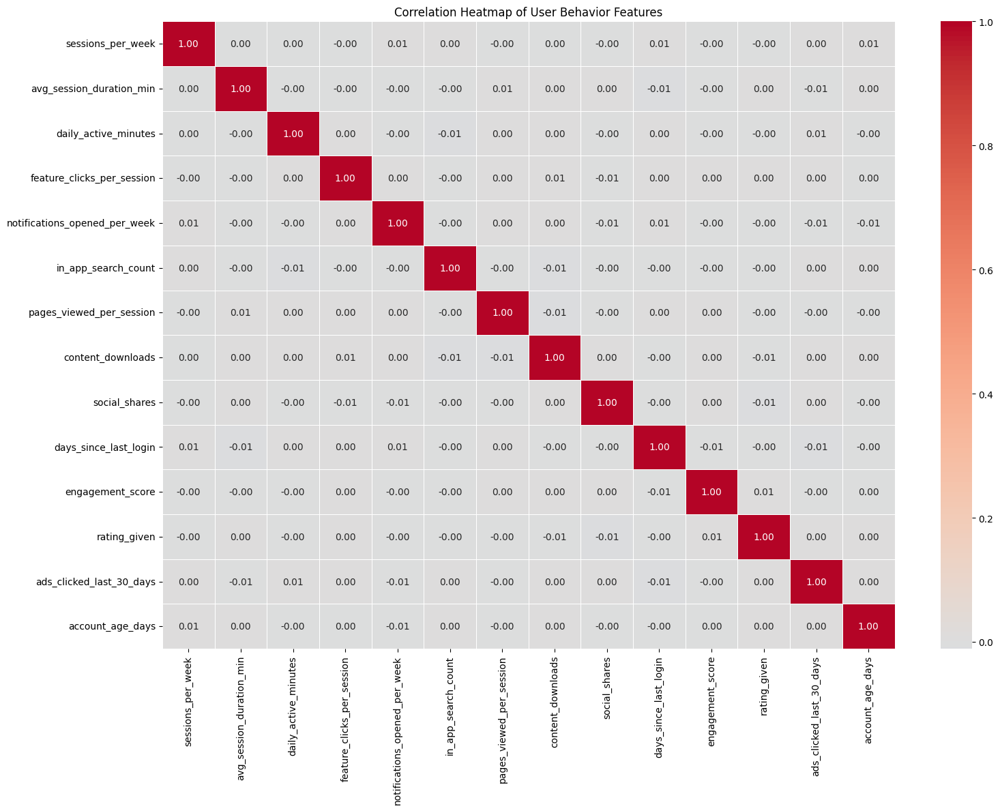

In [15]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of User Behavior Features')
plt.tight_layout()
plt.show()

ONE HOT ENCODING

In [16]:
one_hot_cols = [ "gender","country","device_type","app_version","subscription_type","marketing_source"]

df= pd.get_dummies(df, columns=one_hot_cols, drop_first=True, dtype=int)

SCALING USING STANDARDSCALER

In [17]:
from sklearn.preprocessing import StandardScaler

In [18]:
columns_to_scale = [
   'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'notifications_opened_per_week',
    'in_app_search_count',
    'pages_viewed_per_session',
    'content_downloads',
    'social_shares',
    'days_since_last_login',
     'engagement_score',
    'rating_given',
   'ads_clicked_last_30_days',	'account_age_days','churn_risk_score'
]
scaler = StandardScaler()
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])


UNSUPERVISED MACHINE LEARNING

SPLI DATA FOR TRAIN AND TEST

In [19]:
X_train = df.iloc[0:49000]
X_test = df.iloc[49000:]

Dimensionality Reduction using PCA

Original shape:        user_id  age  sessions_per_week  avg_session_duration_min  \
0       100000   56          -1.060179                 -1.088633   
1       100001   46           0.000113                  1.261914   
2       100002   32           1.413835                 -0.872915   
3       100003   25          -1.060179                 -1.024924   
4       100004   38           0.706974                 -0.033514   
...        ...  ...                ...                       ...   
48995   148995   19           0.000113                 -0.572251   
48996   148996   41           0.353544                  2.065548   
48997   148997   27           1.060405                 -0.429183   
48998   148998   49          -0.706748                  0.035784   
48999   148999   34           0.000113                 -0.452655   

       daily_active_minutes  feature_clicks_per_session  \
0                  0.386849                    0.283336   
1                 -0.160705                   -1.

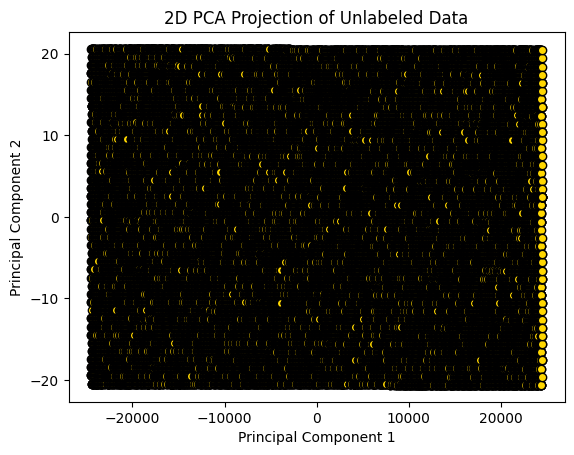

In [28]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_train)

print("Original shape:",X_train)
print("Reduced shape:", X_reduced.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)

# 4. Plot the 2D projection
plt.scatter(X_reduced[:, 0], X_reduced[:, 1],c='gold', edgecolor='k')
plt.title("2D PCA Projection of Unlabeled Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

KMean Cluster

In [29]:
from sklearn.cluster import KMeans
import plotly.express as px

Elbow Graph

In [31]:
cluster =[]
wss = []
for i in range(2,15):
  model = KMeans(i)
  model.fit(X_train)
  cluster.append(i)
  wss.append(model.inertia_)

fig = px.line(x=cluster, y=wss)
fig.show()

In [32]:
model = KMeans(4)
model.fit(X_train)

KMeans(n_clusters=4)

In [33]:
pred = model.predict(X_train)
pred

array([0, 0, 0, ..., 3, 3, 3], shape=(49000,), dtype=int32)

In [43]:
# Drop the 'cluster' column from X_test to match the features used when 'model' was trained
X_test_aligned = X_test.drop(columns=['cluster'], errors='ignore')

pred1 = model.predict(X_test_aligned)
pred1

array([3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,
       3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,

In [44]:
# Use the test set predictions (pred_test) which has 1,000 rows, aligning perfectly with X_test
X_test["cluster"] = pred_test

/tmp/ipykernel_981/495398432.py:2: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



UMAP for cluster analyse

In [ ]:
import umap

In [ ]:
reducer = umap.UMAP(n_components=2, random_state=42)

In [ ]:
embedding = reducer.fit_transform(X_train)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



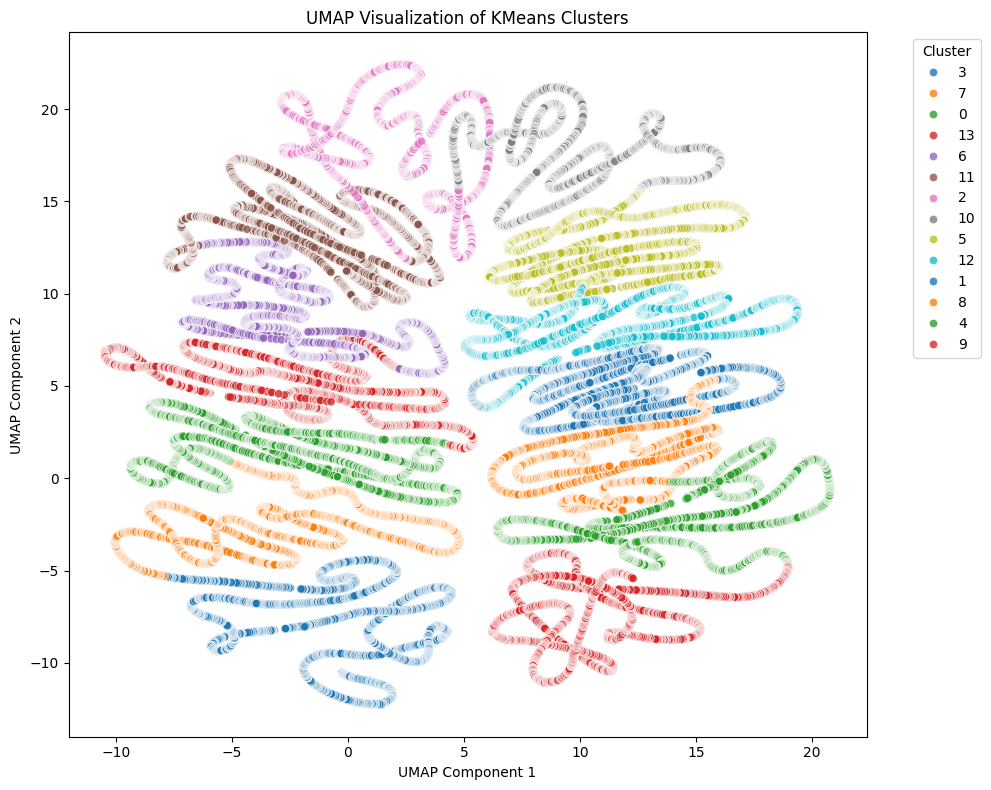

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create a DataFrame for UMAP results
df_umap = pd.DataFrame(embedding, columns=['UMAP 1', 'UMAP 2'])

# Obtain KMeans predictions for X_train (49,000 rows) to match the UMAP embedding length
train_pred = model.predict(X_train)
df_umap['Cluster'] = train_pred.astype(str)

plt.figure(figsize=(10, 8))
sns.scatterplot(
    x='UMAP 1',
    y='UMAP 2',
    hue='Cluster',
    palette='tab10',
    data=df_umap,
    alpha=0.8
)
plt.title('UMAP Visualization of KMeans Clusters')
plt.xlabel('UMAP Component 1')
plt.ylabel('UMAP Component 2')
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Fixing the Clustering Features
We will drop `user_id` from our clustering datasets so that KMeans calculates distances based entirely on actual behavioral features.

In [46]:
# Drop user_id from features as it dominates the clustering distance metric
X_train_clean = X_train.drop(columns=['user_id'], errors='ignore')
X_test_clean = X_test.drop(columns=['user_id', 'cluter'], errors='ignore')

# Re-fit the 4-cluster KMeans model
model_clean = KMeans(n_clusters=4, random_state=42)
model_clean.fit(X_train_clean)

# Predict clusters for the training set
train_clusters = model_clean.predict(X_train_clean)


CLUSTERS WITH TOTAL USERS AND SAMPLES

In [47]:
import numpy as np

# Map the 4 corrected clusters to the training set user IDs
train_users_df = df.iloc[0:49000].copy()
train_users_df['Cluster'] = train_clusters

for cluster in sorted(train_users_df['Cluster'].unique()):
    users = train_users_df[train_users_df['Cluster'] == cluster]['user_id']
    print(f"\nCluster {cluster}")
    print("Total Users:", len(users))
    # Printing only the first 20 IDs to avoid cluttering the output
    print("Sample User IDs:", users.tolist()[:20], "...")


Cluster 0
Total Users: 11747
Sample User IDs: [100002, 100006, 100008, 100009, 100023, 100029, 100030, 100037, 100040, 100049, 100050, 100059, 100062, 100064, 100066, 100068, 100072, 100073, 100079, 100088] ...

Cluster 1
Total Users: 13852
Sample User IDs: [100000, 100005, 100011, 100012, 100019, 100022, 100027, 100032, 100036, 100048, 100051, 100052, 100056, 100061, 100063, 100065, 100070, 100077, 100091, 100092] ...

Cluster 2
Total Users: 13001
Sample User IDs: [100001, 100004, 100007, 100010, 100013, 100015, 100017, 100018, 100021, 100024, 100025, 100026, 100028, 100034, 100039, 100042, 100044, 100045, 100058, 100060] ...

Cluster 3
Total Users: 10400
Sample User IDs: [100003, 100014, 100016, 100020, 100031, 100033, 100035, 100038, 100041, 100043, 100046, 100047, 100053, 100054, 100055, 100057, 100067, 100080, 100082, 100083] ...


PRESENTING USER_ID WITH IT'S CLUSTER

In [48]:
# Assign cluster labels to each user
df['Cluster'] =train_users_df['Cluster']

# Display user ID and cluster assignment
print(df[['user_id', 'Cluster']].head(20))

    user_id  Cluster
0    100000      1.0
1    100001      2.0
2    100002      0.0
3    100003      3.0
4    100004      2.0
5    100005      1.0
6    100006      0.0
7    100007      2.0
8    100008      0.0
9    100009      0.0
10   100010      2.0
11   100011      1.0
12   100012      1.0
13   100013      2.0
14   100014      3.0
15   100015      2.0
16   100016      3.0
17   100017      2.0
18   100018      2.0
19   100019      1.0


 engagement_score  avg_session_duration_min  sessions_per_week

In [49]:
# 1. Map predictions for both training (49k rows) and testing (1k rows) back to df
all_clusters = list(train_clusters) + list(pred_test)
df['Cluster'] = all_clusters

# 2. Use the correct behavioral feature names for aggregation
cluster_analysis = df.groupby('Cluster').agg({
    'engagement_score': 'mean',
    'avg_session_duration_min': 'mean',
    'sessions_per_week': 'mean',
    'churn_risk_score': 'mean'
}).round(2)

print(cluster_analysis)

         engagement_score  avg_session_duration_min  sessions_per_week  \
Cluster                                                                  
0                    0.01                      0.00              -0.01   
1                    0.01                      0.00               0.01   
2                   -0.01                     -0.01              -0.01   
3                   -0.00                      0.01              -0.00   

         churn_risk_score  
Cluster                    
0                   -0.01  
1                   -0.00  
2                    0.01  
3                   -0.00  


In [50]:
cluster_profile = df.groupby('Cluster').agg({
    'engagement_score': 'mean',
    'sessions_per_week': 'mean',
    'avg_session_duration_min': 'mean',
    'churn_risk_score': 'mean'
}).round(2)

print(cluster_profile)

         engagement_score  sessions_per_week  avg_session_duration_min  \
Cluster                                                                  
0                    0.01              -0.01                      0.00   
1                    0.01               0.01                      0.00   
2                   -0.01              -0.01                     -0.01   
3                   -0.00              -0.00                      0.01   

         churn_risk_score  
Cluster                    
0                   -0.01  
1                   -0.00  
2                    0.01  
3                   -0.00  


ADD CLUSTER COLOUMN INTO UNSCALED CLEANED DATASET

In [51]:
df_clean['Cluster'] = df['Cluster'].values

In [52]:
cluster_profile = df_clean.groupby('Cluster').agg({
    'engagement_score': 'mean',
    'sessions_per_week': 'mean',
    'avg_session_duration_min': 'mean',
    'churn_risk_score': 'mean'
}).round(2)

print(cluster_profile)

         engagement_score  sessions_per_week  avg_session_duration_min  \
Cluster                                                                  
0                   65.03               7.98                     13.17   
1                   65.02               8.04                     13.16   
2                   64.79               7.98                     13.05   
3                   64.91               7.99                     13.23   

         churn_risk_score  
Cluster                    
0                     0.5  
1                     0.5  
2                     0.5  
3                     0.5  


In [53]:
print(df_clean.groupby('Cluster')[[
    'engagement_score',
    'sessions_per_week',
    'avg_session_duration_min',
    'churn_risk_score'
]].std().round(2))

         engagement_score  sessions_per_week  avg_session_duration_min  \
Cluster                                                                  
0                   14.80               2.81                      9.01   
1                   14.79               2.85                      9.02   
2                   14.88               2.80                      8.87   
3                   14.90               2.86                      8.88   

         churn_risk_score  
Cluster                    
0                    0.29  
1                    0.29  
2                    0.29  
3                    0.29  


In [55]:
from sklearn.metrics import silhouette_score

# Prepare the scaled features by dropping non-feature columns
features_to_exclude = ['user_id', 'Cluster', 'cluster']
scaled_features = df.drop(columns=[col for col in features_to_exclude if col in df.columns], errors='ignore')

score = silhouette_score(scaled_features, df['Cluster'], sample_size=5000,
                         random_state=42)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.304


Business Insight Generation & Customer Action Mapping

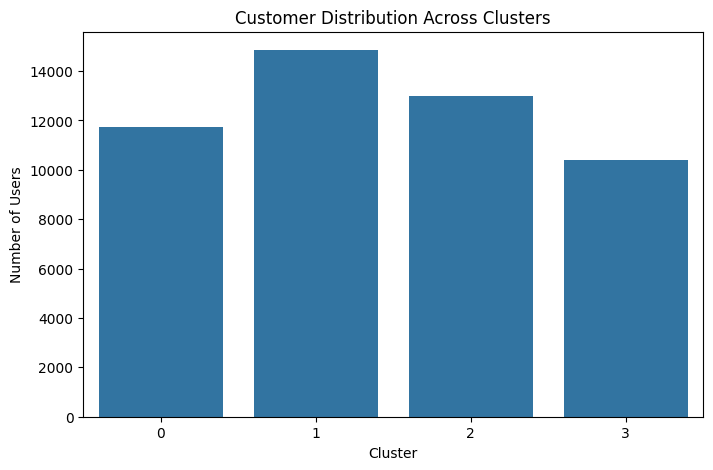

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Cluster')

plt.title('Customer Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Users')

plt.show()

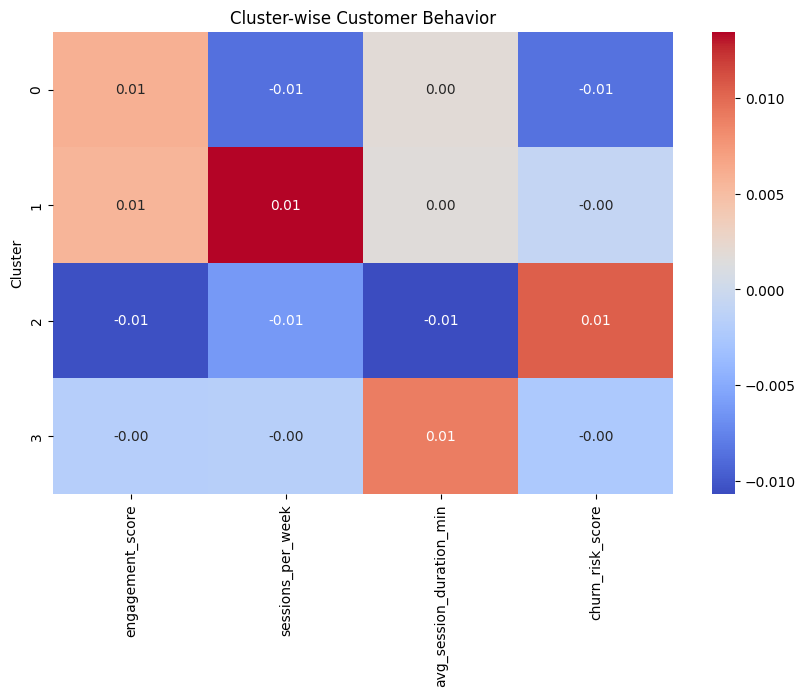

In [57]:
cluster_profile = df.groupby('Cluster')[
    ['engagement_score',
     'sessions_per_week',
     'avg_session_duration_min',
     'churn_risk_score']
].mean()

plt.figure(figsize=(10, 6))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Cluster-wise Customer Behavior')
plt.show()

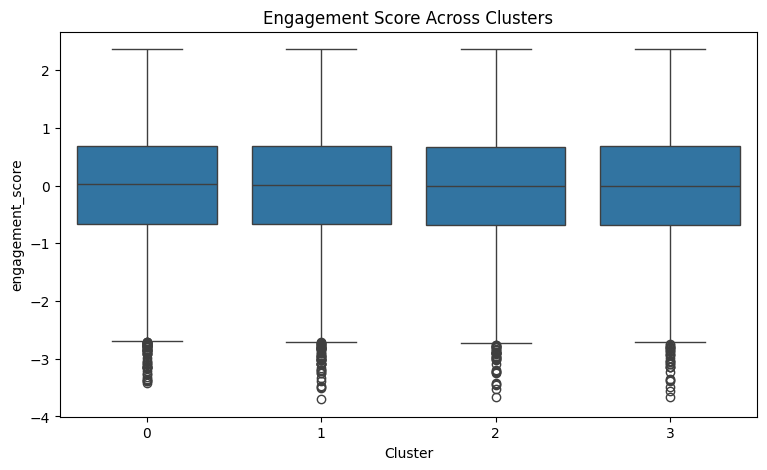

In [59]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Cluster',
    y='engagement_score'
)

plt.title('Engagement Score Across Clusters')
plt.show()

MAPPING USER'S CLUSTOR AND ASSING BUSSION ACTION THAT NEED TO BE TAKEN

In [60]:
action_mapping = {
    0: 'Loyalty Rewards and Premium Offers',
    1: 'Personalized Engagement Campaigns',
    2: 'Retention and Comeback Offers',
    3: 'Re-engagement and Activity Notifications'
}

# Assign actions to customers
df['Business_Action'] = df['Cluster'].map(action_mapping)

# Display customer-level targeting
print(df[['user_id', 'Cluster', 'Business_Action']].head(20))

    user_id  Cluster                           Business_Action
0    100000        1         Personalized Engagement Campaigns
1    100001        2             Retention and Comeback Offers
2    100002        0        Loyalty Rewards and Premium Offers
3    100003        3  Re-engagement and Activity Notifications
4    100004        2             Retention and Comeback Offers
5    100005        1         Personalized Engagement Campaigns
6    100006        0        Loyalty Rewards and Premium Offers
7    100007        2             Retention and Comeback Offers
8    100008        0        Loyalty Rewards and Premium Offers
9    100009        0        Loyalty Rewards and Premium Offers
10   100010        2             Retention and Comeback Offers
11   100011        1         Personalized Engagement Campaigns
12   100012        1         Personalized Engagement Campaigns
13   100013        2             Retention and Comeback Offers
14   100014        3  Re-engagement and Activity Notifi

USER COUNT BASED ON BUSSINESS ACTION

In [61]:
action_summary = df.groupby('Business_Action').agg(
    total_users=('user_id', 'nunique')
).reset_index()

print(action_summary)

                            Business_Action  total_users
0        Loyalty Rewards and Premium Offers        11747
1         Personalized Engagement Campaigns        14852
2  Re-engagement and Activity Notifications        10400
3             Retention and Comeback Offers        13001


LISTING HIGH VALUE CUSTOMERS

In [62]:
high_value = df[
    (df['engagement_score'] > df['engagement_score'].quantile(0.75)) &
    (df['churn_risk_score'] < df['churn_risk_score'].median())
]

print(high_value[['user_id', 'engagement_score', 'churn_risk_score']])

       user_id  engagement_score  churn_risk_score
17      100017          2.362717         -1.007828
24      100024          1.196171         -1.111787
25      100025          0.954909         -1.077134
35      100035          2.069564         -0.453380
46      100046          1.268279         -0.973175
...        ...               ...               ...
49975   149975          1.426649         -0.418727
49977   149977          1.616019         -0.869216
49980   149980          2.362717         -1.111787
49982   149982          0.898974         -1.389011
49993   149993          1.100475         -0.453380

[6103 rows x 3 columns]


LISTING HIGH RISK CUSTOMERS

In [63]:
at_risk = df[
    df['churn_risk_score'] > df['churn_risk_score'].quantile(0.75)
]

print(at_risk[['user_id', 'engagement_score', 'churn_risk_score']])

       user_id  engagement_score  churn_risk_score
1       100001          1.175953          1.279270
6       100006         -0.110550          0.967393
14      100014         -0.917225          1.660453
19      100019          0.272908          1.175311
22      100022          0.893583          1.002046
...        ...               ...               ...
49967   149967         -1.986053          1.625800
49968   149968         -0.841747          1.002046
49990   149990         -1.840488          1.209964
49994   149994         -0.250050          1.348576
49999   149999          0.876735          1.106005

[12365 rows x 3 columns]


SEPERATE USERS TO PROCEED BUSINESS ACTION

In [64]:
action_mapping = {
    0: 'Loyalty Campaign',
    1: 'Engagement Campaign',
    2: 'Retention Campaign',
    3: 'Activation Campaign'
}

df['Business_Action'] = df['Cluster'].map(action_mapping)

# Get customer IDs for each campaign
for cluster in sorted(df['Cluster'].unique()):

    customers = df.loc[
        df['Cluster'] == cluster, 'user_id'
    ].tolist()

    print(f"\nCluster {cluster}")
    print("Business Action:", action_mapping[cluster])
    print("Total Customers:", len(customers))
    print("Customer IDs:", customers[:20])


Cluster 0
Business Action: Loyalty Campaign
Total Customers: 11747
Customer IDs: [100002, 100006, 100008, 100009, 100023, 100029, 100030, 100037, 100040, 100049, 100050, 100059, 100062, 100064, 100066, 100068, 100072, 100073, 100079, 100088]

Cluster 1
Business Action: Engagement Campaign
Total Customers: 14852
Customer IDs: [100000, 100005, 100011, 100012, 100019, 100022, 100027, 100032, 100036, 100048, 100051, 100052, 100056, 100061, 100063, 100065, 100070, 100077, 100091, 100092]

Cluster 2
Business Action: Retention Campaign
Total Customers: 13001
Customer IDs: [100001, 100004, 100007, 100010, 100013, 100015, 100017, 100018, 100021, 100024, 100025, 100026, 100028, 100034, 100039, 100042, 100044, 100045, 100058, 100060]

Cluster 3
Business Action: Activation Campaign
Total Customers: 10400
Customer IDs: [100003, 100014, 100016, 100020, 100031, 100033, 100035, 100038, 100041, 100043, 100046, 100047, 100053, 100054, 100055, 100057, 100067, 100080, 100082, 100083]


PERCENTAGE OF USER AS PER THE ASSIGNED ACTION

In [66]:
campaign_summary['percentage'] = (
    campaign_summary['total_customers'] / df['user_id'].nunique()
) * 100

print(campaign_summary.round(2))

       Business_Action  total_customers  percentage
0  Activation Campaign            10400       20.80
1  Engagement Campaign            14852       29.70
2     Loyalty Campaign            11747       23.49
3   Retention Campaign            13001       26.00


In [67]:
business_mapping = pd.DataFrame({
    'Cluster': [0, 1, 2, 3],

    'Customer_Segment': [
        'Segment 0',
        'Segment 1',
        'Segment 2',
        'Segment 3'
    ],

    'Behavioral_Characteristics': [
        'To be validated using customer metrics',
        'To be validated using customer metrics',
        'To be validated using customer metrics',
        'To be validated using customer metrics'
    ],

    'Business_Objective': [
        'Improve customer loyalty and retention',
        'Increase customer engagement',
        'Reduce potential customer churn',
        'Increase customer activity'
    ],

    'Recommended_Strategy': [
        'Loyalty rewards and exclusive benefits',
        'Personalized recommendations and offers',
        'Comeback offers and retention messages',
        'Activity reminders and feature discovery'
    ],

    'Business_Action': [
        'Loyalty Campaign',
        'Engagement Campaign',
        'Retention Campaign',
        'Activation Campaign'
    ]
})

print(business_mapping)

   Cluster Customer_Segment              Behavioral_Characteristics  \
0        0        Segment 0  To be validated using customer metrics   
1        1        Segment 1  To be validated using customer metrics   
2        2        Segment 2  To be validated using customer metrics   
3        3        Segment 3  To be validated using customer metrics   

                       Business_Objective  \
0  Improve customer loyalty and retention   
1            Increase customer engagement   
2         Reduce potential customer churn   
3              Increase customer activity   

                       Recommended_Strategy      Business_Action  
0    Loyalty rewards and exclusive benefits     Loyalty Campaign  
1   Personalized recommendations and offers  Engagement Campaign  
2    Comeback offers and retention messages   Retention Campaign  
3  Activity reminders and feature discovery  Activation Campaign  
